In [1]:
!pip install ucimlrepo -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

# fetch dataset (ID 891: CDC Diabetes Health Indicators)
cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

# data (as pandas dataframes)
X = cdc_diabetes_health_indicators.data.features
y = cdc_diabetes_health_indicators.data.targets

# Join features and target into one table
df = pd.concat([X, y], axis=1)
target = "Diabetes_binary"
feature_cols = list(X.columns)
binary_features = [c for c in feature_cols if df[c].nunique() == 2]

print("Data loaded:", df.shape)

Data loaded: (253680, 22)


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.81,0.39,0.0,1.0,1.0,1.0,1.0


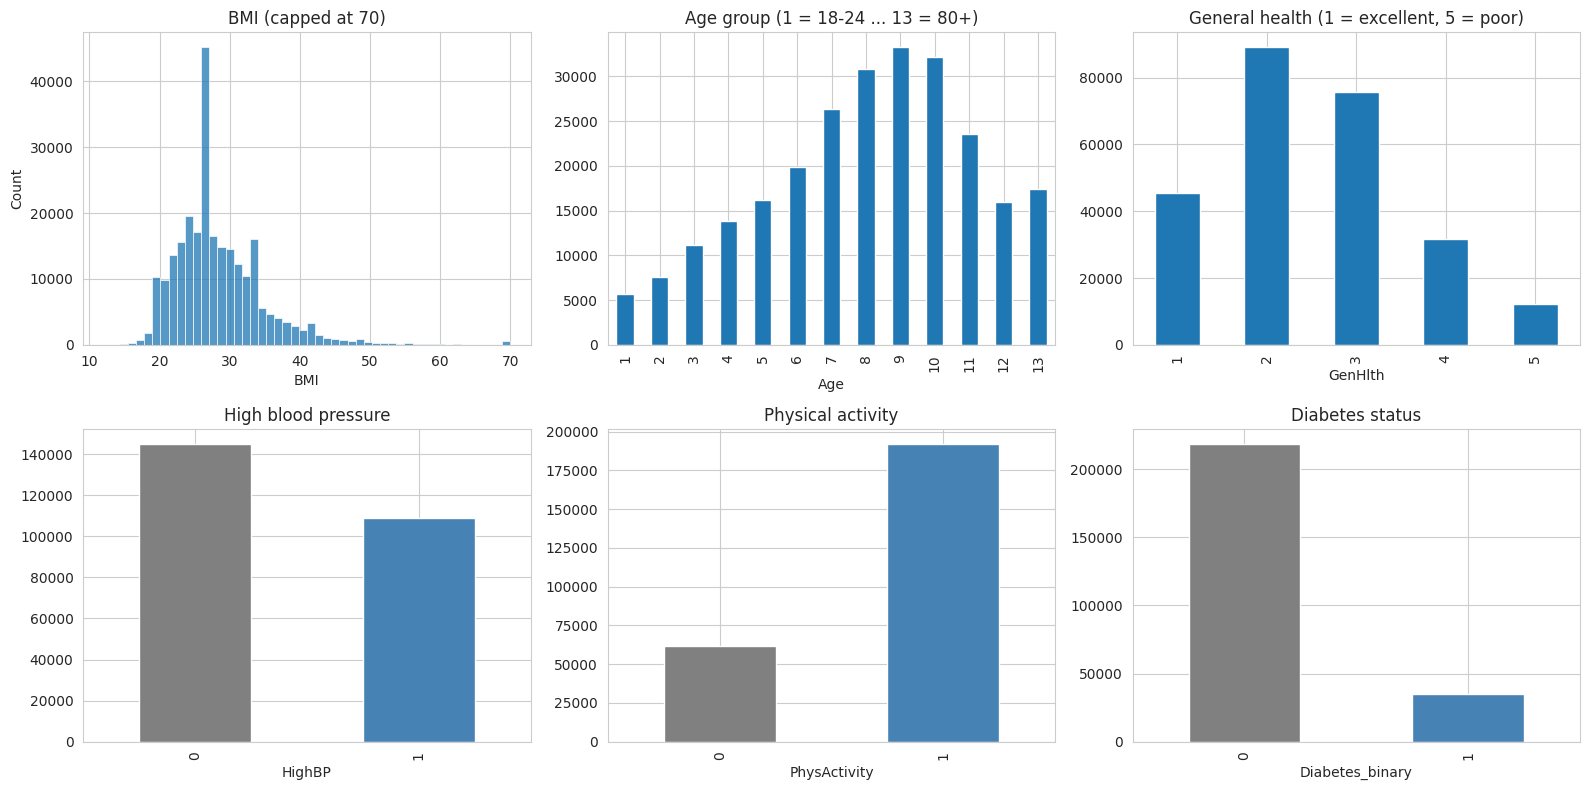

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df["BMI"].clip(upper=70), bins=50, ax=axes[0, 0]); axes[0, 0].set_title("BMI (capped at 70)")
df["Age"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1]); axes[0, 1].set_title("Age group (1 = 18-24 ... 13 = 80+)")
df["GenHlth"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 2]); axes[0, 2].set_title("General health (1 = excellent, 5 = poor)")
df["HighBP"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], color=["grey", "steelblue"]); axes[1, 0].set_title("High blood pressure")
df["PhysActivity"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 1], color=["grey", "steelblue"]); axes[1, 1].set_title("Physical activity")
df[target].value_counts().sort_index().plot(kind="bar", ax=axes[1, 2], color=["grey", "steelblue"]); axes[1, 2].set_title("Diabetes status")
plt.tight_layout()
plt.show()

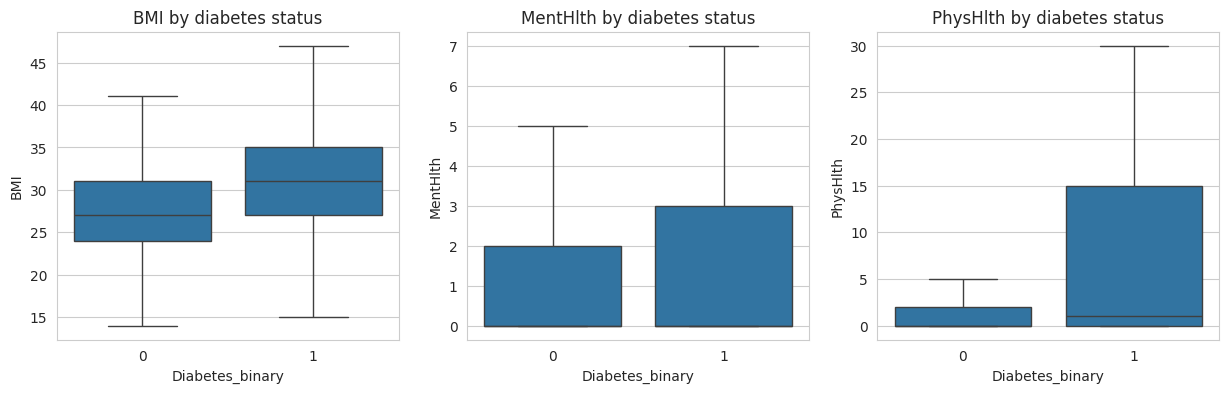

BMI        MentHlth        PhysHlth       
                  mean median     mean median     mean median
Diabetes_binary                                              
0                27.81   27.0     2.98    0.0     3.64    0.0
1                31.94   31.0     4.46    0.0     7.95    1.0

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(x=target, y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(f"{col} by diabetes status")
plt.show()

df.groupby(target)[["BMI", "MentHlth", "PhysHlth"]].agg(["mean", "median"]).round(2)

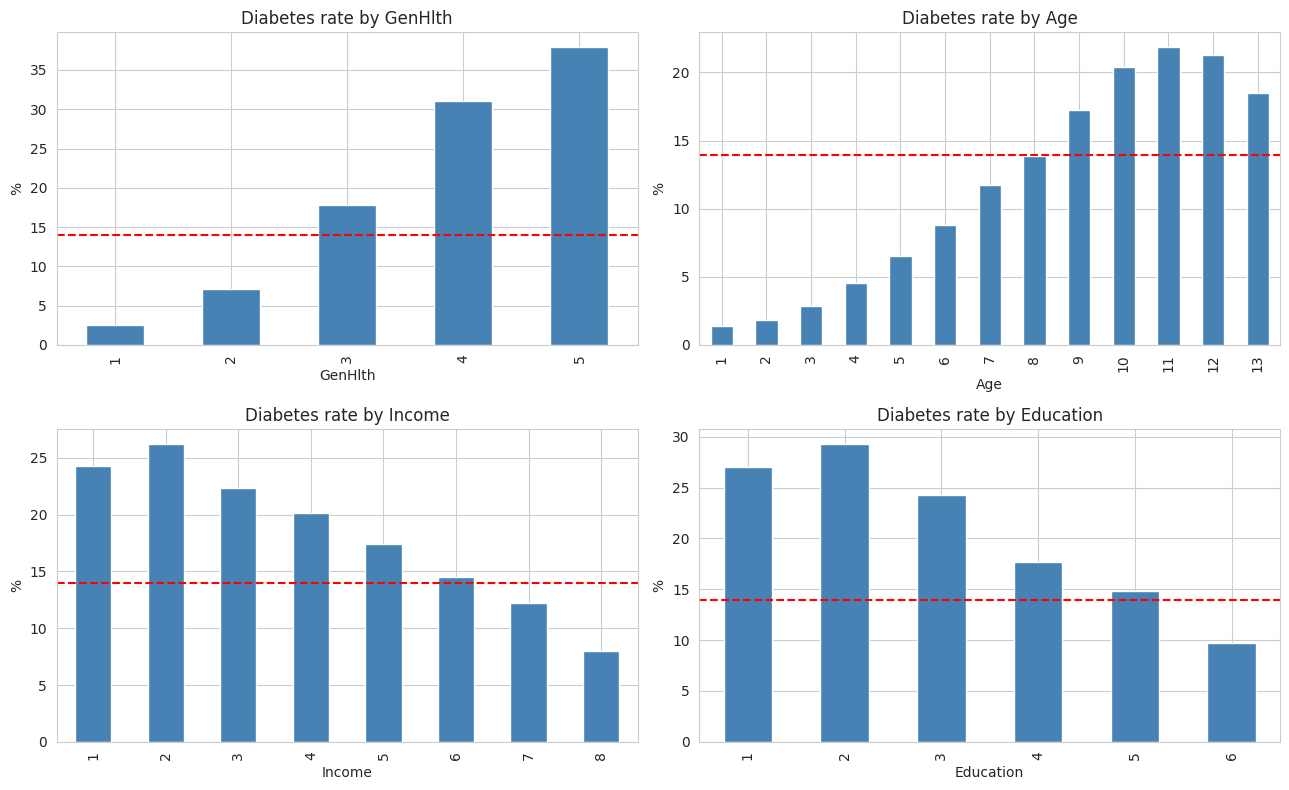

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flatten(), ["GenHlth", "Age", "Income", "Education"]):
    rate = df.groupby(col)[target].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.axhline(df[target].mean() * 100, color="red", linestyle="--")
    ax.set_title(f"Diabetes rate by {col}")
    ax.set_ylabel("%")
plt.tight_layout()
plt.show()

BMI    <18.5  18.5-25  25-30  30-35  35-40   40+
Age                                             
18-39    1.3      1.2    1.8    4.1    7.2  11.5
40-59    4.0      3.5    7.5   13.9   22.7  31.3
60-69    7.8      6.8   14.4   25.3   37.9  45.4
70+      7.7     11.1   19.0   30.4   38.7  48.1


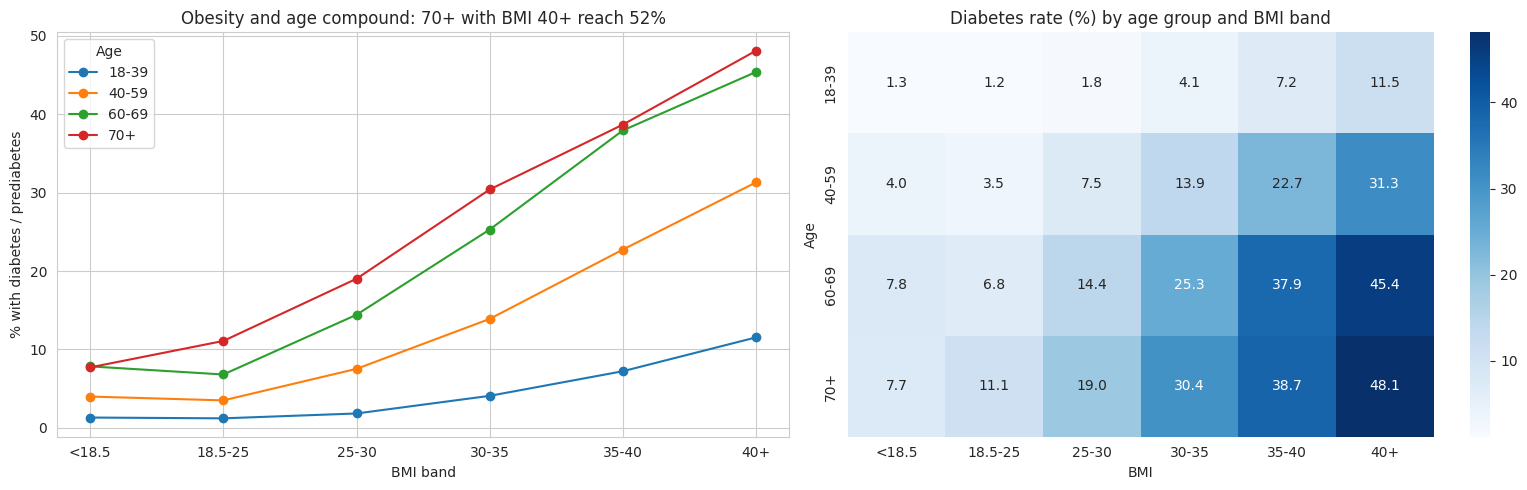

In [8]:
bmi_band = pd.cut(df["BMI"], [0, 18.5, 25, 30, 35, 40, 100], right=False,
                  labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"])
age_group = pd.cut(df["Age"], [0, 4, 8, 10, 13], labels=["18-39", "40-59", "60-69", "70+"])

table = pd.crosstab(age_group, bmi_band, values=df[target], aggfunc="mean") * 100
print(table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
table.T.plot(marker="o", ax=axes[0])
axes[0].set_title("Obesity and age compound: 70+ with BMI 40+ reach 52%")
axes[0].set_xlabel("BMI band"); axes[0].set_ylabel("% with diabetes / prediabetes")
sns.heatmap(table, annot=True, fmt=".1f", cmap="Blues", ax=axes[1])
axes[1].set_title("Diabetes rate (%) by age group and BMI band")
plt.tight_layout()
plt.show()

Rows per number of conditions:
0    97968
1    81002
2    57010
3    15217
4     2483
Name: count, dtype: int64

Diabetes rate (%):
0     3.7
1    12.2
2    26.5
3    36.4
4    47.4
Name: Diabetes_binary, dtype: float64


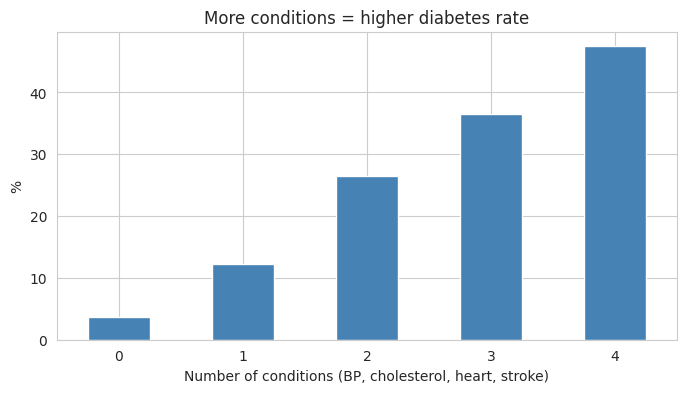

In [9]:
conditions = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]
n_conditions = df[conditions].sum(axis=1)
rate = df.groupby(n_conditions)[target].mean() * 100
print("Rows per number of conditions:")
print(n_conditions.value_counts().sort_index())
print()
print("Diabetes rate (%):")
print(rate.round(1))

rate.plot(kind="bar", color="steelblue")
plt.title("More conditions = higher diabetes rate")
plt.xlabel("Number of conditions (BP, cholesterol, heart, stroke)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

Diabetes rate by sex (%):
Female    13.0
Male      15.2
Name: Diabetes_binary, dtype: float64


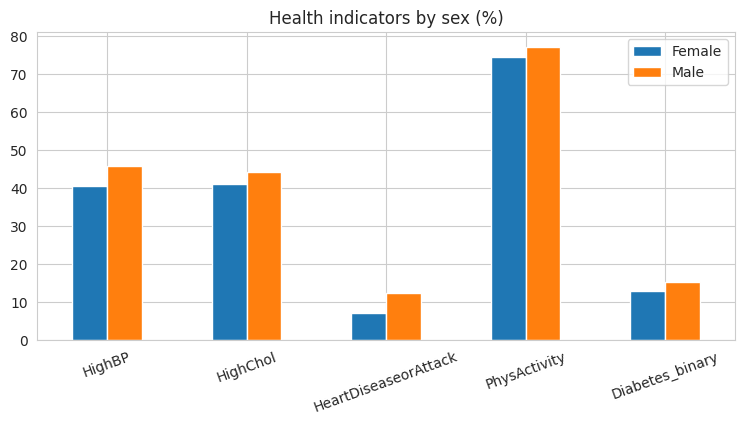

In [10]:
sex_rate = df.groupby("Sex")[target].mean() * 100
sex_rate.index = ["Female", "Male"]
print("Diabetes rate by sex (%):")
print(sex_rate.round(1))

# Prevalence of key conditions by sex
by_sex = df.groupby("Sex")[["HighBP", "HighChol", "HeartDiseaseorAttack", "PhysActivity", target]].mean() * 100
by_sex.index = ["Female", "Male"]
by_sex.T.round(1).plot(kind="bar", figsize=(9, 4))
plt.title("Health indicators by sex (%)")
plt.xticks(rotation=20)
plt.show()

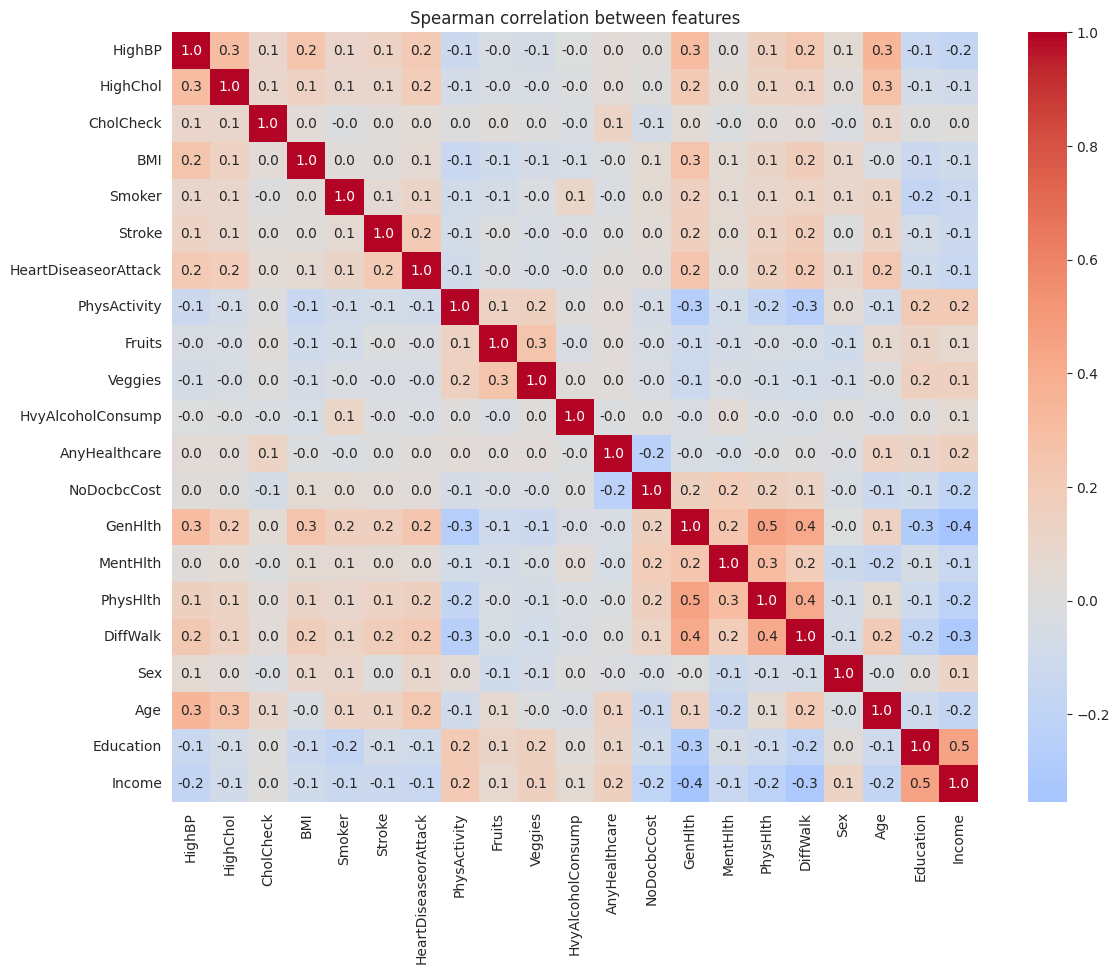

Strongest feature pairs:
Education  Income      0.452
GenHlth    PhysHlth    0.452
           DiffWalk    0.423
PhysHlth   DiffWalk    0.415
GenHlth    Income     -0.354
HighBP     Age         0.345
MentHlth   PhysHlth    0.308
DiffWalk   Income     -0.304
HighBP     GenHlth     0.303
           HighChol    0.298
dtype: float64


In [11]:
plt.figure(figsize=(13, 10))
sns.heatmap(df[feature_cols].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.title("Spearman correlation between features")
plt.show()

c = df[feature_cols].corr(method="spearman")
pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
print("Strongest feature pairs:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(3))

In [13]:
print(df[["BMI", "GenHlth", "Age", "Income", "MentHlth", "PhysHlth"]].agg(["min", "max", "std"]).round(2))
print()
print("Binary features:", len(binary_features), "of", len(feature_cols))

       BMI  GenHlth    Age  Income  MentHlth  PhysHlth
min  12.00     1.00   1.00    1.00      0.00      0.00
max  98.00     5.00  13.00    8.00     30.00     30.00
std   6.61     1.07   3.05    2.07      7.41      8.72

Binary features: 14 of 21


In [14]:
summary = pd.DataFrame({
    "Finding": [
        "Rows / features",
        "Positive class share",
        "Mean BMI: no diabetes vs pre/diabetes",
        "Diabetes rate: excellent vs poor general health",
        "Diabetes rate: 0 vs 4 conditions",
        "Highest-risk group (age x BMI)",
        "Diabetes rate: female vs male",
        "Strongest feature pair (Spearman)",
    ],
    "Value": [
        f"{df.shape[0]:,} / {X.shape[1]}",
        f"{df[target].mean()*100:.1f}%",
        f"{df[df[target]==0]['BMI'].mean():.1f} vs {df[df[target]==1]['BMI'].mean():.1f}",
        f"{df[df['GenHlth']==1][target].mean()*100:.1f}% vs {df[df['GenHlth']==5][target].mean()*100:.1f}%",
        f"{rate.loc[0]:.1f}% vs {rate.loc[4]:.1f}%",
        f"Age 70+ with BMI 40+: {table.loc['70+', '40+']:.1f}%",
        f"{sex_rate['Female']:.1f}% vs {sex_rate['Male']:.1f}%",
        f"{pairs.abs().idxmax()[0]} - {pairs.abs().idxmax()[1]}: {pairs[pairs.abs().idxmax()]:.2f}",
    ],
})
summary

,Finding,Value
0,Rows / features,"253,680 / 21"
1,Positive class share,13.9%
2,Mean BMI: no diabetes vs pre/diabetes,27.8 vs 31.9
3,Diabetes rate: excellent vs poor general health,2.5% vs 37.9%
4,Diabetes rate: 0 vs 4 conditions,3.7% vs 47.4%
5,Highest-risk group (age x BMI),Age 70+ with BMI 40+: 48.1%
6,Diabetes rate: female vs male,13.0% vs 15.2%
7,Strongest feature pair (Spearman),Education - Income: 0.45
